# Matching product names to an item master: four methods compared

> **🤖 Built with substantial AI assistance.** I used an AI coding assistant heavily for this analysis:
> building the four matcher variants, running them side by side on the same inputs, tracing the cases where
> they disagreed, and drafting the comparison write-up. My role was setting the goal, deciding what counts as
> a correct match, reviewing the disputed cases, and choosing the method to adopt. The AI made it practical
> to try four complete approaches instead of one, and the comparison is what exposed each method's blind spots.

**The problem.** A ratings list scores seed hybrids by name, for example `NF52-34RIB`. To use the ratings
in sales tools, each row has to be linked to **every** matching SKU in the product item master. One hybrid can
have many SKUs: different packages, sometimes different trait versions. Names don't line up cleanly:

- Each brand writes its codes differently, and the ratings list and the item master don't always agree with each other.
- Trait suffixes are spelled several ways (`RIB`, `VT2P RIB`, `VT2PRIB`).
- **Sibling hybrids differ by one digit** (`NF52-34` vs. `NF52-36`). One character off is a *different product*.
- Some brands simply aren't in the item master.

> **About the data.** The original compared four complete matching notebooks on a real ratings list and item
> master, with no hand-checked ground truth, so accuracy came from spot checks. Here, brands, codes, and
> traits are **simulated** to reproduce those same difficulties. Because the simulation knows the right
> answer, every method's precision and recall can be **measured**.

In [1]:
import re
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import lightgbm as lgb
from rapidfuzz import fuzz
from rapidfuzz.distance import Levenshtein, JaroWinkler

pd.set_option("display.width", 130)
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False, "font.size": 10})
METHOD_COLORS = {"1 · Rules + edit distance": "#bbbbbb", "2 · N-gram + core": "#e0a21e",
                 "3 · Learned core + trait gate": "#4c8c2b", "4 · LightGBM pair classifier": "#3b6ea8"}

## 1. Simulated item master and ratings list

Six fictional brands, each with its own code style:

| Brand | Item master code | How the ratings list writes it | Wrinkle |
|---|---|---|---|
| Northfield | `NF52-34` | `NF52-34RIB`, `NF 52-34 VT2P` | many one-digit siblings |
| Bluestem | `BS1410`, newer `BS10410` | `BS-1410 GT` | new 5-digit codes |
| Prairie Gold | `PG11B21` | `PG11B21RA` (trait glued on) | trait spellings missing from the dictionary |
| Heartland | `6020Q` | `HL6020Q AMX` | brand prefix only in the ratings list |
| Ironwood | `IW5887` | `IW 5887 SSP` | |
| Summit | *(none)* | `SU4410 AM` | not in the item master at all |

In [2]:
rng = np.random.default_rng(4)

TRAITS = {"Northfield": ["VT2P", "VT2PRIB", "SSP", "TRE"], "Bluestem": ["GT", "GTA", "3110"],
          "Prairie Gold": ["RA", "AM", "AMX", "CONV"], "Heartland": ["AM", "AMX", "Q"],
          "Ironwood": ["VT2P", "SSP", "DGVT2P"], "Summit": ["AM", "Q"]}
# how the ratings list may spell each canonical trait (some spellings are NOT in the dictionary below)
SPELLINGS = {"VT2PRIB": ["VT2PRIB", "RIB", "VT2P RIB"], "TRE": ["TRE", "TRECEPTA"], "AMX": ["AMX", "AMXT"],
             "RA": ["RA", "RAX"], "SSP": ["SSP", "SS"]}
PACKAGES = ["80M BAG", "SSU BOX", "BULK", "50LB", "MINI BULK", "PROBOX"]


def make_codes(brand, n):
    codes = set()
    while len(codes) < n:
        if brand == "Northfield":
            rm, b = rng.integers(42, 70), rng.integers(10, 99)
            codes.add(f"NF{rm}-{b:02d}")
            if rng.random() < 0.45:                                  # one-digit sibling
                codes.add(f"NF{rm}-{(b + rng.choice([-2, 2, 1])) % 100:02d}")
        elif brand == "Bluestem":
            d = rng.integers(1000, 9999)
            codes.add(f"BS{d}" if rng.random() < 0.7 else f"BS1{d}")
            if rng.random() < 0.35:
                codes.add(f"BS{d + rng.choice([-1, 1, 10])}")
        elif brand == "Prairie Gold":
            codes.add(f"PG{rng.integers(10, 19)}{rng.choice(list('ABDK'))}{rng.integers(10, 99)}")
        elif brand == "Heartland":
            codes.add(f"{rng.integers(1000, 9999)}{rng.choice(list('QAR'))}")
        elif brand == "Ironwood":
            codes.add(f"IW{rng.integers(1000, 9999)}")
        else:
            codes.add(f"SU{rng.integers(1000, 9999)}")
    return sorted(codes)


im_rows, catalog = [], []
for brand, n in [("Northfield", 70), ("Bluestem", 70), ("Prairie Gold", 60), ("Heartland", 55), ("Ironwood", 55)]:
    for code_ in make_codes(brand, n):
        traits = rng.choice(TRAITS[brand], size=rng.choice([1, 1, 2]), replace=False)
        for t in traits:
            catalog.append((brand, code_, t))
            for pkg in rng.choice(PACKAGES, size=rng.integers(1, 5), replace=False):
                im_rows.append({"brand": brand, "code": code_, "seed_trait": t,
                                "item_desc": f"{code_} {t} {pkg}"})
item_master = pd.DataFrame(im_rows)
item_master.insert(0, "item_id", [f"I{i:05d}" for i in range(len(item_master))])


def rating_name(brand, code_, trait):
    c = code_
    if brand == "Northfield" and rng.random() < 0.3:
        c = c.replace("NF", "NF ")
    if brand == "Bluestem" and rng.random() < 0.6:
        c = c.replace("BS", "BS-")
    if brand == "Heartland":
        c = "HL" + c
    if brand == "Ironwood" and rng.random() < 0.5:
        c = c.replace("IW", "IW ")
    if trait is None:
        return c
    spelled = rng.choice(SPELLINGS.get(trait, [trait]))
    glue = "" if brand == "Prairie Gold" or rng.random() < 0.4 else " "
    return f"{c}{glue}{spelled}"


ratings, truth_rows = [], []
cat = pd.DataFrame(catalog, columns=["brand", "code", "trait"])
for _, r in cat.sample(360, random_state=1).iterrows():
    trait = None if rng.random() < 0.15 else r.trait
    if trait and rng.random() < 0.08:                                # a trait version that isn't sold
        others = [t for t in TRAITS[r.brand] if t not in set(cat[(cat.code == r.code)].trait)]
        trait = rng.choice(others) if others else trait
    ratings.append({"brand": r.brand, "name": rating_name(r.brand, r.code, trait), "_code": r.code, "_trait": trait})
for code_ in make_codes("Summit", 40):
    ratings.append({"brand": "Summit", "name": rating_name("Summit", code_, rng.choice(TRAITS["Summit"])),
                    "_code": code_, "_trait": None})
for brand in ["Northfield", "Bluestem", "Ironwood"]:                 # rated hybrids never stocked
    for code_ in make_codes(brand, 12):
        if code_ not in set(item_master.code):
            ratings.append({"brand": brand, "name": rating_name(brand, code_, rng.choice(TRAITS[brand])),
                            "_code": code_, "_trait": None})
ratings = pd.DataFrame(ratings).sample(frac=1, random_state=2).reset_index(drop=True)
ratings.insert(0, "rating_id", [f"R{i:04d}" for i in range(len(ratings))])

# ground truth: same hybrid code, and the same trait when the rating states one
t = ratings.merge(item_master, left_on="_code", right_on="code", suffixes=("", "_im"))
t = t[t._trait.isna() | (t._trait == t.seed_trait)]
truth = set(zip(t.rating_id, t.item_id))
rating_true_code = dict(zip(ratings.rating_id, ratings._code))     # kept aside for error analysis only
ratings = ratings.drop(columns=["_code", "_trait"])

In [3]:
print(f"Item master: {len(item_master):,} SKUs for {item_master.code.nunique()} hybrid codes")
print(f"Ratings list: {len(ratings)} rows; true (rating, SKU) pairs: {len(truth):,}; "
      f"rows with at least one true SKU: {len({r for r, _ in truth})}")
item_master.sample(6, random_state=3)

Item master: 985 SKUs for 310 hybrid codes
Ratings list: 436 rows; true (rating, SKU) pairs: 874; rows with at least one true SKU: 338


,item_id,brand,code,seed_trait,item_desc
193,I00193,Northfield,NF66-41,VT2P,NF66-41 VT2P 50LB
740,I00740,Heartland,6475A,Q,6475A Q MINI BULK
58,I00058,Northfield,NF50-30,VT2P,NF50-30 VT2P 80M BAG
682,I00682,Heartland,2014Q,AMX,2014Q AMX 50LB
197,I00197,Northfield,NF67-88,TRE,NF67-88 TRE SSU BOX
633,I00633,Prairie Gold,PG18B94,AM,PG18B94 AM 80M BAG


In [4]:
ratings.sample(8, random_state=5)

,rating_id,brand,name
241,R0241,Northfield,NF 65-54 VT2PRIB
354,R0354,Bluestem,BS-9919GTA
391,R0391,Heartland,HL7981QQ
21,R0021,Prairie Gold,PG14K96RA
318,R0318,Prairie Gold,PG12B31RAX
382,R0382,Heartland,HL8616A AM
358,R0358,Ironwood,IW 5161 VT2P
43,R0043,Ironwood,IW5918


## 2. Shared building blocks

All four methods use the same normalization and the same **trait dictionary**, which maps spellings to a
canonical trait. Like the real one, the dictionary is incomplete: `TRECEPTA`, `AMXT`, and `RAX` aren't in it.

In [5]:
TRAIT_DICT = {"VT2P": "VT2P", "VT2PRIB": "VT2PRIB", "RIB": "VT2PRIB", "VT2P RIB": "VT2PRIB", "SSP": "SSP", "SS": "SSP",
              "TRE": "TRE", "GT": "GT", "GTA": "GTA", "3110": "3110", "RA": "RA", "AM": "AM", "AMX": "AMX",
              "CONV": "CONV", "Q": "Q", "DGVT2P": "DGVT2P"}
ALIASES = sorted(TRAIT_DICT, key=len, reverse=True)


def norm(s):
    return re.sub(r"[^A-Z0-9]", "", str(s).upper())


def split_trait(name):
    """Return (name without a recognized trait suffix, canonical trait or None)."""
    up = str(name).upper().strip()
    for alias in ALIASES:
        if up.endswith(alias) and len(up) > len(alias):
            return norm(up[: -len(alias)]), TRAIT_DICT[alias]
    return norm(up), None


ratings[["stem", "trait"]] = ratings.name.apply(lambda s: pd.Series(split_trait(s)))
item_master["code_norm"] = item_master.code.map(norm)
ratings.sample(6, random_state=5)

,rating_id,brand,name,stem,trait
241,R0241,Northfield,NF 65-54 VT2PRIB,NF6554,VT2PRIB
354,R0354,Bluestem,BS-9919GTA,BS9919,GTA
391,R0391,Heartland,HL7981QQ,HL7981Q,Q
21,R0021,Prairie Gold,PG14K96RA,PG14K96,RA
318,R0318,Prairie Gold,PG12B31RAX,PG12B31RAX,NaN
382,R0382,Heartland,HL8616A AM,HL8616A,AM


## 3. The four methods

### Method 1: hand-written rules + edit distance
A regex per brand pulls out the code; a pair matches when the codes are within **Levenshtein distance < 2**
and the parsed trait equals the SKU's trait. Then each SKU keeps only its single closest rating row.

The rules were written before Bluestem's 5-digit codes existed, and the distance threshold lets one-digit
siblings through.

In [6]:
RULES = {"Northfield": (r"NF\s?(\d{2})-?(\d{2})", lambda m: f"NF{m[1]}-{m[2]}"),
         "Bluestem": (r"BS-?(\d{4})(?!\d)", lambda m: f"BS{m[1]}"),
         "Prairie Gold": (r"PG(\d{2}[A-Z]\d{2})", lambda m: f"PG{m[1]}"),
         "Heartland": (r"HL(\d{4}[A-Z])", lambda m: m[1]),
         "Ironwood": (r"IW\s?(\d{4})", lambda m: f"IW{m[1]}")}


def rule_code(row):
    if row.brand not in RULES:
        return None
    pattern, fmt = RULES[row.brand]
    m = re.search(pattern, row["name"].upper())
    return fmt(m) if m else None


ratings["rule_code"] = ratings.apply(rule_code, axis=1)
c1 = ratings.dropna(subset=["rule_code", "trait"]).merge(item_master, on="brand", suffixes=("", "_im"))
c1["dist"] = [Levenshtein.distance(a, b) for a, b in zip(c1.rule_code, c1.code)]
c1 = c1[(c1.dist < 2) & (c1.trait == c1.seed_trait)]
c1 = c1.sort_values("dist").drop_duplicates("item_id")          # one rating row per SKU
m1 = set(zip(c1.rating_id, c1.item_id))
print(f"Method 1: {len(m1):,} pairs")

Method 1: 633 pairs


### Method 2: character n-grams + learned code core
This one matches on fuzzy text overlap. A pair is a candidate if the rating's character 3-grams are mostly
contained in the SKU's code, **or** the learned code cores (Method 3) agree. It's scored
`0.7 × code similarity + 0.3 × trait agreement`. A trait mismatch only *lowers* the score; it doesn't block
the match. The original used MinHash LSH to find candidates at scale. With a few thousand SKUs, exact
containment is fast enough and gives the same pairs.

In [7]:
def grams(s, n=3):
    return {s[i:i + n] for i in range(len(s) - n + 1)} or {s}


def learn_cut(brand):
    """Grid-search how many leading characters to drop and keep so rating stems hit exactly one code."""
    r = ratings[ratings.brand == brand].stem
    codes = set(item_master.loc[item_master.brand == brand, "code_norm"])
    best, best_hits = (0, 99), -1
    for drop in range(0, 4):
        for keep in range(4, 10):
            cores = r.str[drop:drop + keep]
            hits = sum(1 for c in cores if sum(code.startswith(c) for code in codes if len(code) == len(c)) == 1)
            if hits > best_hits:
                best, best_hits = (drop, keep), hits
    return best


CUTS = {b: learn_cut(b) for b in item_master.brand.unique()}
ratings["core"] = [s[CUTS[b][0]:CUTS[b][0] + CUTS[b][1]] if b in CUTS else s for b, s in zip(ratings.brand, ratings.stem)]
print("Learned (drop, keep) per brand:", CUTS)

c2 = ratings.merge(item_master, on="brand", suffixes=("", "_im"))
c2["contain"] = [len(grams(a) & grams(b)) / len(grams(a)) for a, b in zip(c2.stem, c2.code_norm)]
c2["core_hit"] = c2.core == c2.code_norm
c2 = c2[(c2.contain >= 0.8) | c2.core_hit]
trait_score = np.where(c2.trait.isna(), 0.5, np.where(c2.trait == c2.seed_trait, 1.0, 0.0))
c2["score"] = 0.7 * np.where(c2.core_hit, 1.0, c2.contain) + 0.3 * trait_score
c2 = c2[c2.score >= 0.7]
m2 = set(zip(c2.rating_id, c2.item_id))
print(f"Method 2: {len(m2):,} pairs")

Learned (drop, keep) per brand: {'Northfield': (0, 6), 'Bluestem': (0, 7), 'Prairie Gold': (0, 7), 'Heartland': (2, 5), 'Ironwood': (0, 6)}


Method 2: 1,280 pairs


### Method 3: learned code core + exact match + trait gate
No fuzzy distance at all. The learned core (above) must equal the SKU's code **exactly**. The trait is then
a hard gate:

- If the rating states a trait, the SKU must carry it.
- If it doesn't, the hybrid must exist in only one trait version, so the answer isn't ambiguous.

Every accept or reject gets a reason, which makes the output auditable.

In [8]:
c3 = ratings.merge(item_master, left_on=["brand", "core"], right_on=["brand", "code_norm"], suffixes=("", "_im"))
n_traits = item_master.groupby("code").seed_trait.nunique()
c3["reason"] = np.select(
    [c3.trait.notna() & (c3.trait == c3.seed_trait), c3.trait.notna(), c3.code.map(n_traits).eq(1)],
    ["accept: code + trait", "reject: trait mismatch", "accept: code, single trait version"],
    default="reject: no trait, several versions")
m3 = set(zip(c3.loc[c3.reason.str.startswith("accept"), "rating_id"], c3.loc[c3.reason.str.startswith("accept"), "item_id"]))
print(f"Method 3: {len(m3):,} pairs")
c3.reason.value_counts()

Method 3: 766 pairs


reason
accept: code + trait                  660
reject: trait mismatch                379
reject: no trait, several versions    126
accept: code, single trait version    106
Name: count, dtype: int64

### Method 4: LightGBM pair classifier
This one treats matching as classification. Candidate pairs are any rating-SKU pair from the same brand that
share a run of 2+ digits. Each pair gets string-similarity features, and a LightGBM model scores it.

In practice there was no hand-labeled training set, so the model was trained on **Method 1's output** as
labels. That's what was available, and it's the crux of this method.

In [9]:
def digits(s):
    return re.sub(r"\D", "", s)


cand = ratings.merge(item_master, on="brand", suffixes=("", "_im"))
shared = [any(d[i:i + 2] in dc for i in range(len(d) - 1)) for d, dc in zip(cand.stem.map(digits), cand.code_norm.map(digits))]
cand = cand[shared].copy()

cand["lev"] = [Levenshtein.distance(a, b) for a, b in zip(cand.core, cand.code_norm)]
cand["jaro"] = [JaroWinkler.similarity(a, b) for a, b in zip(cand.stem, cand.code_norm)]
cand["token_set"] = [fuzz.token_set_ratio(a, b) for a, b in zip(cand["name"], cand.item_desc)]
cand["contain"] = [len(grams(a) & grams(b)) / len(grams(a)) for a, b in zip(cand.stem, cand.code_norm)]
cand["digits_equal"] = (cand.stem.map(digits) == cand.code_norm.map(digits)).astype(int)
cand["len_diff"] = (cand.stem.str.len() - cand.code_norm.str.len()).abs()
cand["trait_known"] = cand.trait.notna().astype(int)
cand["trait_equal"] = (cand.trait == cand.seed_trait).astype(int)
FEATS = ["lev", "jaro", "token_set", "contain", "digits_equal", "len_diff", "trait_known", "trait_equal"]
cand["label_m1"] = [p in m1 for p in zip(cand.rating_id, cand.item_id)]
cand["label_true"] = [p in truth for p in zip(cand.rating_id, cand.item_id)]
print(f"{len(cand):,} candidate pairs; {cand.label_m1.sum():,} labeled positive by Method 1")

9,743 candidate pairs; 633 labeled positive by Method 1


In [10]:
rows = ratings.rating_id.sample(frac=1, random_state=0)
train_ids = set(rows[: int(0.7 * len(rows))])
is_train = cand.rating_id.isin(train_ids)


def fit_and_threshold(label):
    clf = lgb.LGBMClassifier(n_estimators=300, learning_rate=0.05, num_leaves=15, min_child_samples=10,
                             random_state=0, verbose=-1)
    clf.fit(cand.loc[is_train, FEATS], cand.loc[is_train, label])
    p = clf.predict_proba(cand.loc[~is_train, FEATS])[:, 1]
    y = cand.loc[~is_train, label].values
    best = max(np.arange(0.2, 0.96, 0.01),                  # threshold with best F1 against these labels
               key=lambda th: 2 * ((p >= th) & y).sum() / max(1, (p >= th).sum() + y.sum()))
    return clf, best


clf_m1, th_m1 = fit_and_threshold("label_m1")
cand["p_m4"] = clf_m1.predict_proba(cand[FEATS])[:, 1]
m4 = set(zip(cand.loc[cand.p_m4 >= th_m1, "rating_id"], cand.loc[cand.p_m4 >= th_m1, "item_id"]))
print(f"Method 4: threshold {th_m1:.2f}, {len(m4):,} pairs")

Method 4: threshold 0.67, 652 pairs


## 4. Results against the truth

Pair-level **precision** (how many accepted pairs are right) and **recall** (how many true pairs were found),
plus how many rating rows got at least one SKU.

In [11]:
def evaluate(pairs, ids=None):
    p = {x for x in pairs if ids is None or x[0] in ids}
    t = {x for x in truth if ids is None or x[0] in ids}
    tp = len(p & t)
    prec, rec = tp / max(1, len(p)), tp / max(1, len(t))
    return {"pairs": len(p), "precision": prec, "recall": rec, "F1": 2 * prec * rec / max(1e-9, prec + rec),
            "rows matched": len({r for r, _ in p})}


methods = dict(zip(METHOD_COLORS, [m1, m2, m3, m4]))
res = pd.DataFrame({k: evaluate(v) for k, v in methods.items()}).T
res.style.format({"pairs": "{:,.0f}", "precision": "{:.1%}", "recall": "{:.1%}", "F1": "{:.1%}",
                  "rows matched": "{:,.0f}"})

,pairs,precision,recall,F1,rows matched
1 · Rules + edit distance,633,95.1%,68.9%,79.9%,244
2 · N-gram + core,"1,280",67.3%,98.6%,80.0%,356
3 · Learned core + trait gate,766,98.7%,86.5%,92.2%,309
4 · LightGBM pair classifier,652,96.2%,71.7%,82.2%,261


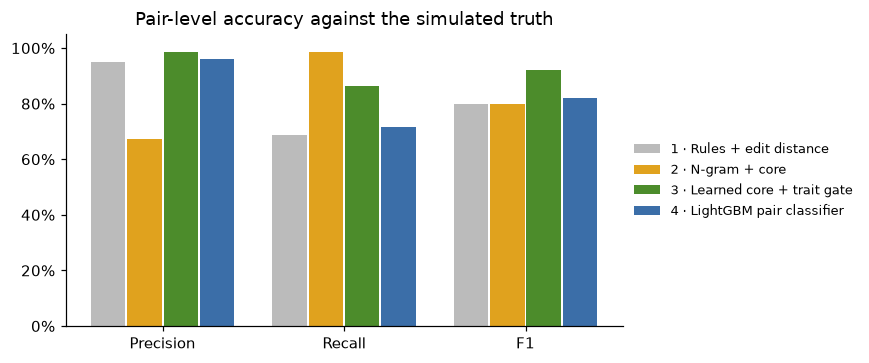

In [12]:
fig, ax = plt.subplots(figsize=(8, 3.4))
x = np.arange(3)
for i, (name, row) in enumerate(res.iterrows()):
    ax.bar(x + (i - 1.5) * 0.2, row[["precision", "recall", "F1"]], width=0.19, color=METHOD_COLORS[name], label=name)
ax.set_xticks(x, ["Precision", "Recall", "F1"])
ax.set_ylim(0, 1.05)
ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f"{v:.0%}"))
ax.legend(frameon=False, fontsize=8.5, loc="center left", bbox_to_anchor=(1, 0.5))
ax.set_title("Pair-level accuracy against the simulated truth")
plt.tight_layout()

## 5. Why each method fails where it does

Sorting every wrong pair into a cause shows each method's blind spot:

- **One-digit sibling:** right brand and trait, but a neighboring hybrid code.
- **Wrong trait version:** right code, wrong trait.
- **Other:** everything else.

,one-digit sibling,wrong trait version,other
1 · Rules + edit distance,31,0,0
2 · N-gram + core,9,409,0
3 · Learned core + trait gate,0,10,0
4 · LightGBM pair classifier,25,0,0


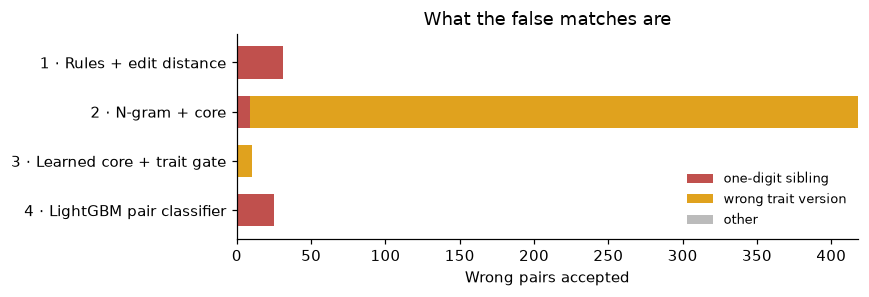

In [13]:
im_code = item_master.set_index("item_id").code


def error_kind(r, i):
    code_, tc = im_code[i], rating_true_code[r]
    if code_ == tc:
        return "wrong trait version"
    if Levenshtein.distance(code_, tc) == 1:
        return "one-digit sibling"
    return "other"


errs = pd.DataFrame({name: pd.Series([error_kind(r, i) for r, i in pairs - truth]).value_counts()
                     for name, pairs in methods.items()}).T.fillna(0).astype(int)
errs = errs.reindex(columns=["one-digit sibling", "wrong trait version", "other"], fill_value=0)
ax = errs.plot(kind="barh", stacked=True, figsize=(8, 2.8), color=["#c0504d", "#e0a21e", "#bbbbbb"], width=0.65)
ax.invert_yaxis()
ax.set(xlabel="Wrong pairs accepted", ylabel="", title="What the false matches are")
ax.legend(frameon=False, fontsize=8.5, loc="lower right")
plt.tight_layout()
errs

**Method 4 inherits Method 1's mistakes.** Its labels came from Method 1, so it learned that a one-digit
difference is acceptable. A quick counterfactual makes this concrete: retrain the *same* model, same
features and threshold search, on correct labels, and compare.

In [14]:
clf_true, th_true = fit_and_threshold("label_true")
p_true = clf_true.predict_proba(cand[FEATS])[:, 1]
m4_true = set(zip(cand.loc[p_true >= th_true, "rating_id"], cand.loc[p_true >= th_true, "item_id"]))

test_ids = set(ratings.rating_id) - train_ids                   # score on held-out rating rows only
cmp = pd.DataFrame({"LightGBM, labels from Method 1": evaluate(m4, test_ids),
                    "LightGBM, correct labels": evaluate(m4_true, test_ids),
                    "Method 3 (no training)": evaluate(m3, test_ids)}).T
cmp[["precision", "recall", "F1"]].style.format("{:.1%}")

,precision,recall,F1
"LightGBM, labels from Method 1",97.5%,76.4%,85.7%
"LightGBM, correct labels",99.6%,98.5%,99.0%
Method 3 (no training),100.0%,91.9%,95.8%


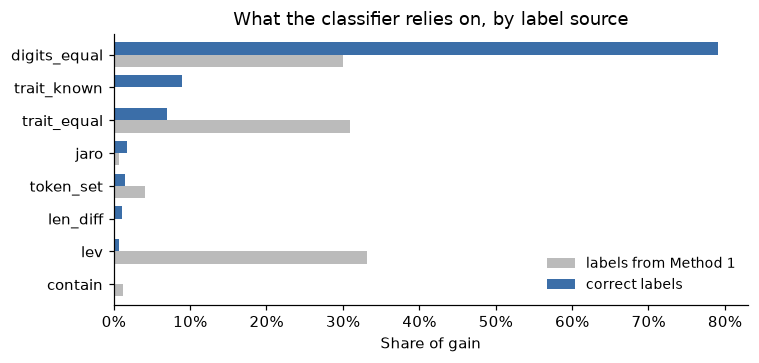

In [15]:
imp = pd.DataFrame({"labels from Method 1": clf_m1.booster_.feature_importance("gain"),
                    "correct labels": clf_true.booster_.feature_importance("gain")}, index=FEATS)
imp = (imp / imp.sum()).sort_values("correct labels")
ax = imp.plot(kind="barh", figsize=(7, 3.4), color=["#bbbbbb", "#3b6ea8"], width=0.75)
ax.xaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f"{v:.0%}"))
ax.set(title="What the classifier relies on, by label source", xlabel="Share of gain")
ax.legend(frameon=False, fontsize=9)
plt.tight_layout()

Same model, same features, same threshold search. Trained on correct labels, the classifier becomes the
**most accurate method in the comparison**. Its attention also moves: from edit distance (imitating Method 1)
to whether the digits match *exactly*. The algorithm was never the problem; the labels were.

## 6. Disagreements are the review queue

In the original comparison the most useful output wasn't any single method. It was the **short list of rating
rows where Method 3 and Method 4 disagree**. Those lists were small and full of real findings: trait spellings
missing from the dictionary, code formats the rules didn't cover, near-miss hybrids.

In [16]:
rows3, rows4 = {r for r, _ in m3}, {r for r, _ in m4}
only4, only3 = rows4 - rows3, rows3 - rows4
print(f"Rows matched only by LightGBM: {len(only4)}  |  only by Method 3: {len(only3)}  |  neither: "
      f"{len(set(ratings.rating_id) - rows3 - rows4)}")
q = ratings[ratings.rating_id.isin(only3 | only4)].assign(
    matched_by=lambda d: np.where(d.rating_id.isin(only4), "LightGBM only", "Method 3 only"),
    right_answer=lambda d: d.rating_id.map(lambda r: rating_true_code[r] if r in {x for x, _ in truth}
                                            else "(not in item master)"))
q[["brand", "name", "trait", "matched_by", "right_answer"]].sort_values(["matched_by", "brand"]).head(12)

Rows matched only by LightGBM: 4  |  only by Method 3: 52  |  neither: 123


,brand,name,trait,matched_by,right_answer
98,Heartland,HL4424Q,Q,LightGBM only,4424Q
108,Heartland,HL1279Q,Q,LightGBM only,1279Q
198,Heartland,HL6048Q,Q,LightGBM only,6048Q
38,Northfield,NF45-48VT2P RIB,VT2PRIB,LightGBM only,(not in item master)
14,Bluestem,BS-4400,NaN,Method 3 only,BS4400
30,Bluestem,BS-39763110,3110,Method 3 only,BS3976
73,Bluestem,BS5047,NaN,Method 3 only,BS5047
155,Bluestem,BS-70223110,3110,Method 3 only,BS7022
176,Bluestem,BS-62023110,3110,Method 3 only,BS6202
178,Bluestem,BS-51023110,3110,Method 3 only,BS5102


## What I'd adopt

| | Rules + edit distance | N-gram + core | Learned core + trait gate | LightGBM |
|---|---|---|---|---|
| Precision | lets siblings through | trait not enforced | **highest without labels** | inherits label errors; best with good labels |
| Coverage | misses new formats | **highest** | high | depends on labels |
| Explainability | readable but many rules | score parts visible | **a reason per decision** | probability only |
| New brands | new regex each time | adapts | **adapts** | needs labels |

- **Make the exact-code method with a trait gate (Method 3) the matcher of record now.** It needs no
  labels, it's the most precise of the four as they stand, every decision is explainable, and it adapts to
  new brands without new code. Its weak spot is an incomplete trait dictionary, which is easy to see and fix.
- **Route disagreements to a person.** That small queue is where the real fixes come from: dictionary gaps,
  code formats the rules missed, and near-miss hybrids.
- **Turn the reviews into labels, then retrain the classifier.** A few hundred hand-checked pairs, starting
  with the disagreement queue, would replace Method 1's flawed labels. On correct labels the classifier was
  the best method here, so it could graduate from second opinion to matcher.
- **Measure, don't spot-check.** The original comparison had no ground truth. With known answers, the
  choice between methods stops being a judgment call.

*Original: four PySpark matching notebooks (regex + Levenshtein, MinHashLSH, learned-core exact match,
LightGBM), compared with substantial AI assistance. This version: pandas, RapidFuzz, LightGBM on simulated
brands and SKUs, prepared with AI assistance.*